# Who adds threat before the shot?

A case study of **128,484 recorded actions across 64 matches** in the 2018 men's FIFA World Cup. This notebook compares how players and teams moved the ball into more threatening areas, then groups players by their on-ball profiles.

![StatsBomb logo](../assets/statsbomb.svg)

Data provided by [StatsBomb Open Data](https://github.com/hudl/open-data). The action snapshot uses SPADL and socceraction's [expected threat model](https://socceraction.readthedocs.io/en/latest/documentation/valuing_actions/xT.html). Before fitting the threat surface, we orient both teams to attack in the same direction. We aggregate the model's rated possession-preserving moves, using the signed change in pitch-zone threat. Unrated actions, including shots and failed moves, contribute zero to these totals. This convention describes the value of completed moves while leaving out the cost of turnovers and the value of shooting.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from socceraction.spadl.config import field_length, field_width
from socceraction.xthreat import ExpectedThreat
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
if not (root / "data" / "processed").is_dir():
    root = root.parent
data = root / "data" / "processed"

actions = pd.read_csv(data / "actions_xt.csv", usecols=[
    "game_id", "player_id", "player_name", "team_id", "team_name",
    "type_name", "type_id", "result_name", "result_id", "home_team",
    "start_x", "start_y", "end_x", "end_y",
])
# The shipped SPADL coordinates use the home team's attacking direction.
away = actions["team_name"].ne(actions["home_team"])
for column in ("start_x", "end_x"):
    actions.loc[away, column] = field_length - actions.loc[away, column]
for column in ("start_y", "end_y"):
    actions.loc[away, column] = field_width - actions.loc[away, column]
shots = actions.loc[actions["type_name"].eq("shot")]
assert shots.groupby(away)["start_x"].median().gt(field_length / 2).all()

model = ExpectedThreat()
model.fit(actions)
actions["xt_value"] = pd.Series(model.rate(actions), index=actions.index).fillna(0)
appearances = pd.read_csv(data / "player_appearances.csv", usecols=[
    "game_id", "player_id", "team_id", "minutes_played",
])
player_keys = ["player_id", "team_id"]
appearance_keys = ["game_id", *player_keys]
assert not appearances.duplicated(appearance_keys).any()
print(f"{len(actions):,} actions across {actions['game_id'].nunique()} matches")

# iterations:  44
128,484 actions across 64 matches


## Which actions and teams account for completed-move threat?

The action table shows both total xT and xT per attempted action. The denominator includes unsuccessful attempts, which contribute zero to the numerator. The team table uses xT per match so that reaching later rounds does not automatically increase the rate.

In [2]:
by_action = actions.groupby("type_name").agg(
    attempts=("xt_value", "size"),
    total_xt=("xt_value", "sum"),
    xt_per_attempt=("xt_value", "mean"),
)
display(by_action.loc[["pass", "cross", "dribble"]].round(4))

teams = actions.groupby("team_name").agg(
    matches=("game_id", "nunique"), total_xt=("xt_value", "sum"),
)
teams["xt_per_match"] = teams["total_xt"] / teams["matches"]
display(teams.nlargest(5, "xt_per_match").round(3))

,attempts,total_xt,xt_per_attempt
type_name,,,
pass,56438,42.9438,0.0008
cross,1305,25.7195,0.0197
dribble,52731,28.4731,0.0005


,matches,total_xt,xt_per_match
team_name,,,
Germany,3,5.718,1.906
Brazil,5,6.565,1.313
Spain,4,5.086,1.271
Serbia,3,3.369,1.123
Belgium,7,7.283,1.040


## Who added the most threat?

The total leaderboard rewards tournament output. The rate leaderboard uses a minimum of 270 minutes and includes only player-team records whose action appearances all match a minutes record. The rate remains sensitive to role, opponent and game state.

,player,team,total_xt
0,Neymar da Silva Santos Junior,Brazil,1.799
1,Joshua Kimmich,Germany,1.613
2,Kevin De Bruyne,Belgium,1.332
3,Eden Hazard,Belgium,1.175
4,Thomas Meunier,Belgium,1.011


,player,team,minutes_played,xt_per_90
0,Joshua Kimmich,Germany,295,0.492
1,Neymar da Silva Santos Junior,Brazil,483,0.335
2,Toni Kroos,Germany,295,0.278
3,Dušan Tadić,Serbia,274,0.243
4,Raphaël Adelino José Guerreiro,Portugal,389,0.231


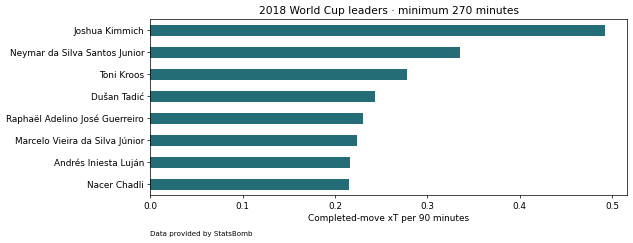

In [3]:
moves = actions.dropna(subset=["player_id"]).copy()
moves["pass_attempt"] = moves["type_name"].eq("pass")
moves["carry_action"] = moves["type_name"].eq("dribble")
moves["final_third_move"] = (
    moves["type_name"].isin(["pass", "cross", "dribble"])
    & moves["result_name"].eq("success")
    & moves["end_x"].ge(field_length * 2 / 3)
)
player_actions = moves.groupby(player_keys).agg(
    player=("player_name", "first"), team=("team_name", "first"),
    total_xt=("xt_value", "sum"), actions=("xt_value", "size"),
    pass_attempts=("pass_attempt", "sum"), carry_actions=("carry_action", "sum"),
    final_third_moves=("final_third_move", "sum"),
)

minutes = appearances.groupby(player_keys)["minutes_played"].sum()
players = player_actions.join(minutes)
minutes_coverage = moves[appearance_keys].drop_duplicates().merge(
    appearances[appearance_keys], on=appearance_keys, how="left", indicator=True, validate="one_to_one",
)
missing = minutes_coverage.loc[minutes_coverage["_merge"].eq("left_only"), player_keys]
eligible = players.loc[players["minutes_played"].ge(270) & ~players.index.isin(pd.MultiIndex.from_frame(missing))].copy()
eligible["xt_per_90"] = eligible["total_xt"] * 90 / eligible["minutes_played"]

display(players.nlargest(5, "total_xt")[["player", "team", "total_xt"]].reset_index(drop=True).round(3))
display(eligible.nlargest(5, "xt_per_90")[["player", "team", "minutes_played", "xt_per_90"]].reset_index(drop=True).round(3))

leaders = eligible.nlargest(8, "xt_per_90").sort_values("xt_per_90")
ax = leaders.plot.barh(x="player", y="xt_per_90", legend=False, figsize=(10, 4), color="#256D76")
ax.set_xlabel("Completed-move xT per 90 minutes")
ax.set_ylabel("")
ax.set_title("2018 World Cup leaders · minimum 270 minutes")
ax.text(0, -0.23, "Data provided by StatsBomb", transform=ax.transAxes, fontsize=8)
plt.tight_layout()
plt.show()

## Which players have similar on-ball profiles?

Fit K-means to standardized rates for passes, carries, final-third moves and completed-move xT. A three-cluster solution is used for illustration. Silhouette scores for nearby choices describe separation in this sample. The clusters mix role, tactics and tournament context, and can guide video review when combined with position and team context.

In [4]:
rate_columns = ["pass_attempts", "carry_actions", "final_third_moves"]
rates = eligible[rate_columns].mul(90 / eligible["minutes_played"], axis=0).add_suffix("_per_90")
features = rates.join(eligible["xt_per_90"])
scaled = StandardScaler().fit_transform(features)
models = {k: KMeans(n_clusters=k, n_init=20, random_state=42).fit(scaled) for k in (2, 3, 4, 5)}
display(pd.Series({k: silhouette_score(scaled, model.labels_) for k, model in models.items()}, name="silhouette").round(3))
clusters = features.assign(cluster=models[3].labels_).groupby("cluster")
display(clusters.mean().assign(players=clusters.size()).round(3))

2    0.366
3    0.338
4    0.362
5    0.322
Name: silhouette, dtype: float64

,pass_attempts_per_90,carry_actions_per_90,final_third_moves_per_90,xt_per_90,players
cluster,,,,,
0,45.968,42.713,20.067,0.076,114
1,23.921,21.419,9.728,0.037,121
2,65.221,67.344,53.430,0.200,16


## Interpretation

This is an in-sample descriptive analysis. The threat surface was fit and applied to the same tournament on a 16 × 12 pitch grid, and the model omits defensive actions, off-ball contributions and the value of shooting. Action frequency affects totals, while team tactics and selection affect per-90 rates. For a cross-competition scouting study, fit the threat surface on a separate reference sample and check whether role-adjusted profiles and clusters are stable across seasons.